# 04 · EDA multivariado: fundamentales con las herramientas del curso (parte 1)

**Términos que se usan en este notebook:** [P/E](../docs/entrega_1/glosario.md) (precio ÷ utilidad por acción: cuántos años de utilidades paga el precio), [P/E normalizado](../docs/entrega_1/glosario.md) (precio ÷ EPS promedio de los 12 trimestres más recientes ya publicados; promediar varios años evita que un año excepcional haga parecer barata una acción que no lo es), [EPS](../docs/entrega_1/glosario.md) (utilidad por acción), [EPS TTM](../docs/entrega_1/glosario.md) (utilidad por acción de los últimos 12 meses), [P/B](../docs/entrega_1/glosario.md) (precio ÷ valor en libros por acción), [ROE](../docs/entrega_1/glosario.md), [margen operativo](../docs/entrega_1/glosario.md), [deuda/patrimonio](../docs/entrega_1/glosario.md), [filed](../docs/entrega_1/glosario.md) (fecha en que la SEC publicó el dato; nada en t usa un dato con filed > t), [split](../docs/entrega_1/glosario.md) (división de cada acción en varias, sin cambiar el valor de la empresa), [quintil](../docs/entrega_1/glosario.md) (cada uno de los 5 grupos de igual tamaño que resultan de ordenar los valores de menor a mayor), [percentil expansivo](../docs/entrega_1/glosario.md) (percentil del valor de hoy dentro de toda su historia hasta hoy, sin mirar al futuro), [quintil por fecha](../docs/entrega_1/glosario.md) (quintiles de las 21 empresas en cada fecha, ordenadas por el percentil propio del P/E normalizado), [bootstrap por empresa](../docs/entrega_1/glosario.md) (remuestreo con reemplazo de empresas completas; conserva el solapamiento de ventanas de una misma empresa), [bootstrap por bloques](../docs/entrega_1/glosario.md) (remuestreo de tramos consecutivos de fechas; conserva la dependencia dentro de una misma fecha), [IC](../docs/entrega_1/glosario.md) (intervalo de confianza al 95 %), [exceso sobre el XLP](../docs/entrega_1/glosario.md) (retorno de la acción menos el del [XLP](../docs/entrega_1/glosario.md) en la misma ventana; dentro del sector, aisla la diferencia frente al choque común) y [censura](../docs/entrega_1/glosario.md) (una observación con resultado todavía no ocurrido, en P2 y P3 las fechas de los últimos 3 años).

**Objetivo.** EDA multivariado de las 21 empresas de la industria piloto (consumo defensivo) juntas: su valoración y su retorno a 3 años. Las dos primeras preguntas de la rama fundamental, con la [plantilla de inferencia](../docs/entrega_1/04_enfoque_analitico.md) del profesor: umbral práctico → H0/H1 y α → prueba con sus supuestos verificados → estimación con IC antes del p-value → tamaño del efecto con IC → dos decisiones (estadística y de negocio) → implicación y limitaciones. Las [reglas de series de tiempo](../notebooks/03_eda_univariado.ipynb) de nb03 §0 se mantienen aquí: nada en t usa un dato publicado después de t.

**Punto del enunciado que cubre.** Punto 6 (entendimiento de los datos, 35 %), rama multivariada: tablas y gráficos que relacionan varias variables al mismo tiempo (P/E normalizado × tiempo × empresa × retorno).

**Tabla de equivalencias pregunta de negocio → sección (orden P1–P6).** P2 → §2, P3 → §3, P4 → §5, P5 → §6 (§4–§6 llegan en las tareas 8a y 8b: continúa en §4).

**Qué alimenta.** Las lecturas fundamentales comparativas de los 6 niveles del producto (percentil propio del P/E normalizado para el nivel de "barata frente a su historia"; descomposición en precio y utilidad promedio para distinguir rebote, normalización y trampa de valor).


In [1]:
import json, sys, time, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
sys.path.insert(0, "."); import comunes as cm      # nbconvert ejecuta el kernel en notebooks/, donde está comunes.py
sns.set_theme(style="whitegrid"); pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220); pd.set_option("display.max_rows", 200)

# Constantes del notebook (qué significan y por qué ese valor: docs/entrega_1/04_enfoque_analitico.md §4.5)
HORIZONTE_ANIOS   = 3           # años: ventana de valor de P2 y P3 (horizonte típico del inversor de largo plazo)
HORIZONTE         = 12          # trimestres de 3 años; una observación por empresa y trimestre calendario
HORIZONTES_SENS   = (2, 4)      # sensibilidades (sin decisión); P3 añade 1 año (exploración previa que motivó el horizonte)
UMBRAL_P2         = 0.03        # diferencia anualizada en log del Δlog(P/E normalizado): estimado ÷ 3; ≈ 9 % en 3 años
UMBRAL_P3         = 0.05        # diferencia anualizada en log del exceso sobre el XLP: estimado ÷ 3; ≈ 16 % en 3 años
VENTANA_NORM      = 12          # trimestres del promedio del EPS (3 años; Graham y Dodd 1934; Shiller 1998)
ANTIGUEDAD_MAX    = 548         # días desde el cierre del último trimestre a partir de los cuales el dato se considera rancio
QUINTIL           = 0.2         # fracción de empresas de cada extremo en cada fecha (quintil barato ≤ 0,2; caro > 0,8)
HIST_MIN_PERCENTIL = 52         # semanas mínimas para calcular el percentil expansivo (un año bursátil)
MIN_EMPRESAS_FECHA = 15         # una fecha entra a los quintiles solo con ≥ 15 empresas con dato (regla fijada antes de estimar)
REPS_BOOT         = 1000        # réplicas del bootstrap (percentiles al 95 % ya estables; curso)
RNG_SEMILLA       = 42          # semilla reproducible para todas las remuestras
ALFA              = 0.05        # α del curso; equivale al IC95
NIVEL_IC          = 0.95        # nivel del IC
Z_80              = 2.80        # z aproximado para el MDE a potencia 80 % (prueba unilateral, α 0,05)
BLOQUE_FECHAS     = 4           # bloque del bootstrap por fechas trimestrales (sensibilidad; 1 año = 4 trimestres)

ASSETS = cm.DIR_ASSETS; ASSETS.mkdir(parents=True, exist_ok=True)
print("constantes definidas; carpeta de figuras:", ASSETS)


constantes definidas; carpeta de figuras: /Users/lgualtero/Projects/Personal/uniandes/data-science-applied/proyecto_final/entregables/entrega_1/assets


## 0.1 Carga de datos

Se cargan tres instantáneas de `data/snapshots/`: `precios_semanales_sd` (precio **sin ajuste por dividendos**: refleja lo que paga el inversor en spot, es el numerador correcto del P/E), `precios_semanales` (precio ajustado por dividendos: el que corresponde al retorno total del inversor, se usa en §3 para P3) y `ratios_ttm` (una fila por cierre de trimestre con los flujos TTM, los saldos, las acciones y los ratios, cada uno con su columna `filed_<ratio>`). También `splits`, que lleva el EPS y el valor en libros a las acciones de hoy. Toda instantánea se filtra con `cm.tickers() + ['XLP']` al cargarla, así una instantánea vieja no contamina nada.

In [2]:
acciones = cm.tickers()                                   # 21 empresas de consumo defensivo
cols_px = acciones + ["XLP"]                               # el XLP entra en §3 como referencia del sector
sem_sd = cm.cargar_snapshot("precios_semanales_sd")        # precio sin ajuste por dividendos (numerador del P/E)
sem_sd = sem_sd[sem_sd.ticker.isin(cols_px)].copy()
sem_ad = cm.cargar_snapshot("precios_semanales")           # precio ajustado por dividendos (retorno total, §3 P3)
sem_ad = sem_ad[sem_ad.ticker.isin(cols_px)].copy()
ttm = cm.cargar_snapshot("ratios_ttm")                      # ratios TTM con su filed_<ratio>
ttm = ttm[ttm.ticker.isin(acciones)].copy()
splits_all = cm.cargar_snapshot("splits")                   # un split lleva el EPS y el valor en libros a las acciones de hoy
splits_all = splits_all[splits_all.ticker.isin(acciones)].copy()

# Normalizar la precisión de todas las fechas a datetime64[ns] (los parquet traen ms/us y merge_asof exige igual precisión)
for _df in (sem_sd, sem_ad):
    _df["fecha"] = _df["fecha"].astype("datetime64[ns]")
for _c in ttm.columns:
    if str(ttm[_c].dtype).startswith("datetime64"):
        ttm[_c] = ttm[_c].astype("datetime64[ns]")
splits_all["fecha"] = splits_all["fecha"].astype("datetime64[ns]")

print(f"precios semanales sd:   {sem_sd.shape[0]:,} filas × {sem_sd.ticker.nunique()} tickers "
      f"({sem_sd.fecha.min().date()} a {sem_sd.fecha.max().date()})")
print(f"precios semanales ad:   {sem_ad.shape[0]:,} filas × {sem_ad.ticker.nunique()} tickers")
print(f"ratios_ttm:             {ttm.shape[0]:,} filas × {ttm.ticker.nunique()} tickers "
      f"(cierres {ttm['end'].min().date()}–{ttm['end'].max().date()})")
print(f"splits (desde {cm.INICIO}):", len(splits_all[splits_all.fecha >= cm.INICIO]),
      "en", splits_all[splits_all.fecha >= cm.INICIO].ticker.nunique(), "empresas")


precios semanales sd:   20,416 filas × 22 tickers (2009-01-05 a 2026-10-12)
precios semanales ad:   20,416 filas × 22 tickers
ratios_ttm:             1,434 filas × 21 tickers (cierres 2009-05-31–2026-09-05)
splits (desde 2009-01-01): 10 en 9 empresas


## 0.2 Funciones de este notebook

Las usa solo este notebook; lo que varios notebooks comparten (universo, carga, bootstrap) vive en `comunes.py`.

**`ajustar_por_splits`** lleva `eps_ttm`, `bvps` y `eps_prom_3a` a las acciones de hoy: cada valor se divide por el producto de los splits con `fecha` posterior a **su propia** fecha `filed_<ratio>` (nb02 §3; fecha por ratio). Un detalle del `eps_prom_3a`: nb01 ya lo construye como "promedio del EPS trimestral de los 12 últimos trimestres ÷ acciones del último trimestre de la ventana", así que **dentro** de la ventana un split queda neutralizado; pero las acciones del último trimestre de la ventana son las de ese trimestre, **no las de hoy**, así que un split **posterior** a `filed_eps_prom_3a` sí hay que dividirlo (si no, se compararía precio en acciones de hoy con EPS en acciones de ayer). La función hace exactamente eso: no duplica el ajuste de los splits dentro de la ventana.

**`ultimo_publicado`** devuelve, para cada semana, el último valor del concepto con `filed_<col>` ≤ esa semana (merge_asof hacia atrás), con empates resueltos por el trimestre más reciente. Un dato con más de `ANTIGUEDAD_MAX` días desde el cierre de su último trimestre se marca como rancio y queda vacío (temporalidad: #9 de los 10-Q, nb02 §3).

**`multiplos_semanales`** arma el panel semanal por ticker con precio sin dividendos, P/E (EPS TTM), P/E normalizado (EPS promedio de 3 años), P/B y las columnas de contexto (ROE, margen operativo, deuda/patrimonio), cada una con su `filed` de origen (los ratios con EPS ≤ 0 o patrimonio ≤ 0 ya quedan vacíos en nb01).

**`percentil_expansivo`** es el percentil del valor de hoy dentro de **toda** su historia hasta hoy; con `min_periods = 52` semanas (un año) un percentil con menos historia queda vacío.

In [3]:
def ajustar_por_splits(r, splits):
    """Lleva eps_ttm/bvps/eps_prom_3a a las acciones de hoy: divide por los splits posteriores a SU fecha de publicación.

    nb01 ya neutraliza los splits DENTRO de la ventana del eps_prom_3a (todos los trimestres se dividen por las
    acciones del último trimestre de la ventana), así que no hay doble división: aquí se corrigen solo los splits
    POSTERIORES a esa fecha, para alinear con el precio actual (sin dividendos, pero ajustado por splits).
    """
    out = r.copy()
    if splits is None or splits.empty:
        return out
    fechas = pd.to_datetime(splits["fecha"]).to_numpy()
    razones = splits["ratio"].to_numpy(dtype=float)
    for col in ("eps_ttm", "bvps", "eps_prom_3a"):
        factor = out[f"filed_{col}"].map(
            lambda f: 1.0 if pd.isna(f) else float(np.prod(razones[fechas > np.datetime64(f)])))
        out[col] = out[col] / factor
    return out


def ultimo_publicado(fechas_precio, r, col):
    """Para cada semana, el último valor de `col` ya publicado (filed_<col> ≤ fecha); empate → trimestre más reciente.

    #9 de los 10-Q (temporalidad): un dato de más de 548 días desde el cierre de su último trimestre es rancio → vacío.
    """
    f = (r[["end", col, f"filed_{col}"]].dropna(subset=[f"filed_{col}"])
           .sort_values([f"filed_{col}", "end"], kind="stable")
           .drop_duplicates(f"filed_{col}", keep="last"))
    m = pd.merge_asof(pd.DataFrame({"fecha": fechas_precio.astype("datetime64[ns]")}),
                      f.rename(columns={f"filed_{col}": "filed"})
                       .assign(filed=lambda d: d.filed.astype("datetime64[ns]"))
                       .assign(end=lambda d: d["end"].astype("datetime64[ns]")),
                      left_on="fecha", right_on="filed", direction="backward")
    rancio = (m["fecha"] - m["end"]).dt.days > ANTIGUEDAD_MAX
    return m[col].where(~rancio).to_numpy()


def multiplos_semanales(precios_sd, r, cols=("eps_ttm", "bvps", "eps_prom_3a", "roe_ttm",
                                             "margen_operativo_ttm", "deuda_patrimonio")):
    """Panel semanal por ticker: precio sin dividendos, P/E (EPS TTM), P/E normalizado (EPS promedio 3 años, R7),
    P/B, y ROE/margen/deuda como contexto. Cada columna llega con SU propio filed_<col> (sin look-ahead).
    EPS ≤ 0 → P/E sin sentido (ya vacío desde nb01)."""
    m = precios_sd[["fecha", "close"]].dropna().sort_values("fecha").reset_index(drop=True)
    for col in cols:
        m[col] = ultimo_publicado(m["fecha"].to_numpy("datetime64[ns]"), r, col)
    m["pe"]      = m["close"] / m["eps_ttm"].where(m["eps_ttm"] > 0)
    m["pe_norm"] = m["close"] / m["eps_prom_3a"].where(m["eps_prom_3a"] > 0)   # R7: "barata frente a su historia"
    m["pb"]      = m["close"] / m["bvps"].where(m["bvps"] > 0)
    return m


def percentil_expansivo(serie, min_obs=HIST_MIN_PERCENTIL):
    """Percentil del valor de hoy dentro de TODA su historia hasta hoy (no mira al futuro)."""
    def _pct(w):
        if np.isnan(w[-1]):
            return np.nan
        v = w[~np.isnan(w)]
        return float((v <= w[-1]).mean()) if len(v) else np.nan
    return serie.expanding(min_periods=min_obs).apply(_pct, raw=True)


## 1. Panel de múltiplos semanales (técnica del curso: EDA multivariado no gráfico)

Para cada ticker se arma su panel semanal con `multiplos_semanales(precios_sd, ajustar_por_splits(ratios, splits))`, se concatenan en un solo panel largo (`fecha`, `ticker`, columnas), y se agrega `pct_norm` = `percentil_expansivo` del P/E normalizado (percentil del valor de hoy dentro de toda su historia hasta hoy, con mínimo de 52 semanas). Es el insumo de todo el resto del notebook.

In [4]:
paneles = []
for t in acciones:
    pr = sem_sd[sem_sd.ticker == t].copy()
    rt = ttm[ttm.ticker == t].copy()
    sp = splits_all[splits_all.ticker == t]
    rt_adj = ajustar_por_splits(rt, sp)
    panel_t = multiplos_semanales(pr, rt_adj)
    panel_t["ticker"] = t
    panel_t["pct_norm"] = percentil_expansivo(panel_t["pe_norm"])
    paneles.append(panel_t)
panel = pd.concat(paneles, ignore_index=True)
print(f"panel semanal: {len(panel):,} filas × {panel.ticker.nunique()} tickers")
print(f"rango: {panel.fecha.min().date()} a {panel.fecha.max().date()}")

cobertura = panel.groupby("ticker").agg(
    semanas_pe      = ("pe", lambda s: s.notna().sum()),
    semanas_pe_norm = ("pe_norm", lambda s: s.notna().sum()),
    semanas_pb      = ("pb", lambda s: s.notna().sum()),
    inicio_pe_norm  = ("pe_norm", lambda s: panel.loc[s.index[s.notna()], "fecha"].min() if s.notna().any() else pd.NaT),
).round(0)
print()
print("Cobertura por empresa (primera columna: nunca sin EPS TTM; segunda: necesita 12 trimestres):")
print(cobertura.to_string())
print()
print(f"Primera semana con P/E normalizado disponible en el panel: {panel[panel.pe_norm.notna()].fecha.min().date()}")


panel semanal: 19,488 filas × 21 tickers
rango: 2009-01-05 a 2026-10-12

Cobertura por empresa (primera columna: nunca sin EPS TTM; segunda: necesita 12 trimestres):
        semanas_pe  semanas_pe_norm  semanas_pb inicio_pe_norm
ticker                                                        
ADM            834              782         884     2011-08-29
CAG            714              652         837     2011-07-25
CHD            806              764         845     2012-02-27
CL             846              794         582     2011-08-01
CLX            842              790         703     2011-08-29
COST           835              783         878     2011-10-17
GIS            823              797         838     2011-07-11
HSY            372              295         411     2011-08-15
KMB            832              780         721     2011-11-07
KO             833              781         868     2011-10-31
KR             851              787         890     2011-09-19
MDLZ           

/var/folders/s5/8t1wl51171ldl81_d8s8bgh80000gp/T/ipykernel_30808/2577925663.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  ).round(0)


**Lectura (2–4 frases con cifras).** El panel reúne las 21 empresas con una media de ~900 semanas de precio por empresa; la cobertura del P/E (EPS TTM) ronda las 850 semanas en la mayoría (STZ queda sin EPS porque le faltan las acciones en `ratios_ttm` desde nb01, y HSY se queda sin EPS a partir de 2015 por la misma razón). La cobertura del P/E normalizado es menor (necesita 12 trimestres y el percentil exige al menos un año de historia): la primera semana con dato llega hacia **2012–2013** y la cobertura por empresa queda en ~700 semanas en las que entran al estudio. El P/B tiene cobertura intermedia (depende del valor en libros, que sí existe para STZ).

## 2. P2 — ¿el "barata frente a su historia" es temporal? (horizonte de 3 años)

**Lector sin finanzas (en lenguaje simple):** cuando una acción tiene un P/E (precio ÷ utilidad) **bajo frente a su propia historia** se habla de "barata frente a su historia". ¿Eso tiende a corregirse (el múltiplo sube, en 3 años, más que el de las que están caras)? Si sí, el nivel de entrada que marca "barata frente a su historia" es informativo para el inversor; si no, es ruido.

**Por qué el P/E normalizado (en lugar del P/E TTM).** Un año de utilidades excepcionales (bueno o malo) puede hacer que una acción parezca barata o cara sin serlo; promediar varios años de utilidades evita esa ilusión. El P/E normalizado es precio ÷ **EPS promedio de los 12 trimestres más recientes ya publicados** (`eps_prom_3a`). La convención viene de Graham y Dodd (1934), que recomendaban 5–10 años, y Campbell y Shiller (1998, DOI 10.3905/jpm.24.2.11) usan 10 años. Aquí se usan 3 años porque los fundamentales estructurados en EDGAR empiezan en 2009 (limitación de datos; se declara en §2.9). El P/E con EPS TTM sigue siendo el P/E "actual" del producto; se usa como contexto y en el panel semanal.

### 2.1 Paso 0: umbral práctico

En la plantilla del profesor el paso 0 fija, **antes** de ver el resultado, la diferencia mínima que cambiaría la decisión. Aquí: la diferencia anualizada en log (estimado del Δlog(P/E normalizado) a 3 años ÷ 3) entre el quintil barato y el caro debe superar `UMBRAL_P2 = 0,03` (≈ 9 % en 3 años). En palabras: *si la valoración de las baratas no sube al menos un 9 % más que la de las caras en 3 años, "barata frente a su historia" no anuncia una normalización que valga la pena esperar*.

### 2.2 H0, H1 y α

- **H0:** el cambio medio de log(P/E normalizado) a 3 años es igual en el quintil barato y en el caro de cada fecha.
- **H1:** el barato sube su P/E normalizado más que el caro (prueba unilateral).
- **α = 0,05** (curso), equivalente a un IC del 95 %.
- **Decisión estadística:** se rechaza H0 si el IC por empresa de la diferencia excluye 0.
- **Decisión de negocio:** accionable si el límite inferior del IC anualizado (÷ 3) supera `UMBRAL_P2`; si lo cruza, "efecto real, pero de magnitud incierta"; si no se rechaza H0, no accionable (misma regla que nb03).

La **H0 equivale** a "el múltiplo se mueve como un paseo aleatorio". Puede rechazarse por **regresión a la media** (un valor extremo con una parte de azar tiende a quedar menos extremo después); por eso la pregunta real la responden la decisión de negocio (¿la diferencia supera el 9 % en 3 años?) y la descomposición en precio y utilidad (¿el movimiento viene del precio, de la utilidad promedio o de ambos?).

### 2.3 Unidad y grupos (una observación por empresa y trimestre calendario)

Los 10-Q y 10-K de las 21 empresas llegan en fechas distintas. Para ordenar a todas en la misma fecha sin mirar al futuro se usa el **último día de cada trimestre calendario**: en cada fecha trimestral, por empresa, se toma la **última semana del panel con fecha ≤ ese día** (merge_asof hacia atrás) con solo lo publicado hasta ese día (sin look-ahead; fechas trimestrales fijadas en). En cada fecha, las 21 empresas se ordenan por su `pct_norm` propio y se parten en 5 grupos iguales (`q = rank(pct=True)`). El **quintil barato** son las ~4 empresas con `q ≤ 0,2` y el **caro** las ~4 con `q > 0,8`.

In [5]:
fechas_trim = pd.date_range(cm.INICIO, panel.fecha.max(), freq="QE")
# Para cada empresa y fecha trimestral, la última semana del panel con fecha ≤ ese día (sin futuro)
piezas = []
for t, g in panel.groupby("ticker"):
    g = g.sort_values("fecha")
    f_df = pd.DataFrame({"fecha_trim": fechas_trim})
    m = pd.merge_asof(f_df, g, left_on="fecha_trim", right_on="fecha", direction="backward",
                      tolerance=pd.Timedelta(days=10))
    m["ticker"] = t
    piezas.append(m)
pf = pd.concat(piezas, ignore_index=True)
pf = pf.dropna(subset=["fecha"])                                           # fechas antes del inicio de precios: fuera
print(f"panel trimestral bruto: {len(pf):,} filas × {pf.ticker.nunique()} tickers "
      f"({pf.fecha_trim.min().date()}–{pf.fecha_trim.max().date()})")


panel trimestral bruto: 1,491 filas × 21 tickers (2009-03-31–2026-09-30)


In [6]:
# Para P2: Δlog(P/E normalizado) de la fecha t a la fecha t+12 trimestres (3 años)
pf_sorted = pf.sort_values(["ticker", "fecha_trim"]).reset_index(drop=True)
pf_sorted["pe_norm_fut"] = pf_sorted.groupby("ticker")["pe_norm"].shift(-HORIZONTE)
pf_sorted["close_fut"]   = pf_sorted.groupby("ticker")["close"].shift(-HORIZONTE)
pf_sorted["eps_prom_3a_fut"] = pf_sorted.groupby("ticker")["eps_prom_3a"].shift(-HORIZONTE)
pf_sorted["dlog_pe_norm"] = np.log(pf_sorted["pe_norm_fut"]) - np.log(pf_sorted["pe_norm"])
pf_sorted["dlog_precio"]  = np.log(pf_sorted["close_fut"])  - np.log(pf_sorted["close"])
pf_sorted["dlog_eps3a"]   = np.log(pf_sorted["eps_prom_3a_fut"]) - np.log(pf_sorted["eps_prom_3a"])

# Quintiles por fecha SOBRE las empresas con pct_norm disponible en esa fecha
pf_sorted["pct_norm_rank"] = pf_sorted.groupby("fecha_trim")["pct_norm"].rank(pct=True, method="average")
pf_sorted["quintil"] = pd.cut(pf_sorted["pct_norm_rank"], bins=[-0.001, QUINTIL, 1 - QUINTIL, 1.001],
                               labels=["barato", "intermedio", "caro"])

# Regla: una fecha entra a los quintiles solo si tiene >= 15 empresas con pct_norm disponible (fijada antes)
cnt_por_fecha = pf_sorted.dropna(subset=["pct_norm"]).groupby("fecha_trim")["ticker"].nunique()
fechas_ok = cnt_por_fecha[cnt_por_fecha >= MIN_EMPRESAS_FECHA].index
fechas_excluidas = cnt_por_fecha[(cnt_por_fecha > 0) & (cnt_por_fecha < MIN_EMPRESAS_FECHA)]
print(f"Fechas trimestrales con al menos una empresa con P/E normalizado: {len(cnt_por_fecha)}")
print(f"Fechas con >= {MIN_EMPRESAS_FECHA} empresas (regla fijada antes de estimar): {len(fechas_ok)}")
print("Fechas excluidas por la regla (empresas < 15):")
print(fechas_excluidas.to_string() if len(fechas_excluidas) else "  (ninguna)")


Fechas trimestrales con al menos una empresa con P/E normalizado: 57
Fechas con >= 15 empresas (regla fijada antes de estimar): 56
Fechas excluidas por la regla (empresas < 15):
fecha_trim
2012-09-30    11


In [7]:
# Panel analizable de P2: filas con 3 años de futuro, quintil asignado y la fecha pasa la regla
P2 = pf_sorted[pf_sorted["fecha_trim"].isin(fechas_ok)
               & pf_sorted["dlog_pe_norm"].notna()
               & pf_sorted["quintil"].isin(["barato", "caro"])].copy()
P2["quintil"] = P2["quintil"].astype(str)       # pandas 3: evita categorías vacías en groupby
# Reporte de n por quintil, número de empresas y tabla empresa × quintil (antes de estimar)
print(f"Panel P2 (3 años de futuro, con quintil barato o caro): {len(P2)} filas, "
      f"{P2.ticker.nunique()} empresas, {P2.fecha_trim.nunique()} fechas")
print(f"Horizonte efectivo: {P2.fecha_trim.min().date()} a {P2.fecha_trim.max().date()}")
print()
print("n por quintil:")
print(P2.groupby("quintil").size().to_string())
print()
print("Empresas distintas por quintil:")
print(P2.groupby("quintil")["ticker"].nunique().to_string())
print()
print("Tabla empresa × quintil (número de fechas, antes de estimar):")
tab_eq = P2.groupby(["ticker", "quintil"]).size().unstack(fill_value=0).sort_values("barato", ascending=False)
print(tab_eq.to_string())

# Nota de la revisión del plan: nb02 §6.1 contó 44 fechas y 840 observaciones empresa-fecha (quintiles de las 5
# categorías); aquí se usan solo los extremos (barato y caro), ≈ 2/5 del total, por eso el n cae a ≈ 336.
# Si el conteo de fechas difiere de 44 se imprime la razón arriba (fechas_excluidas).


Panel P2 (3 años de futuro, con quintil barato o caro): 303 filas, 20 empresas, 44 fechas
Horizonte efectivo: 2012-12-31 a 2023-09-30

n por quintil:
quintil
barato    135
caro      168

Empresas distintas por quintil:
quintil
barato    18
caro      19

Tabla empresa × quintil (número de fechas, antes de estimar):
quintil  barato  caro
ticker               
TSN          22     0
KR           21     2
PM           14     3
MO           13    10
MDLZ         10     6
GIS           9     4
CAG           7     1
WMT           7    15
MKC           6    13
CHD           6     8
ADM           6     6
COST          5    13
KMB           4     3
KO            1    16
CLX           1    13
PEP           1    19
CL            1     5
SYY           1    18
HSY           0     1
PG            0    12


In [8]:
# Diferencia muestral con P3: P2 exige pe_norm_fut (no vacío) y P3 exige el precio ajustado futuro.
# Se imprime cuántas filas P2 no tendrán resultado en P3 por falta de precio ajustado futuro.
# (El merge con precios_semanales se hace en §3; aquí basta con el conteo del panel de P2.)
print(f"Filas con dlog_pe_norm válido en el panel trimestral: "
      f"{int(pf_sorted['dlog_pe_norm'].notna().sum())}")
print(f"Filas con dlog_precio válido (misma ventana, precio SIN dividendos): "
      f"{int(pf_sorted['dlog_precio'].notna().sum())}")
print(f"Filas con dlog_eps3a válido: {int(pf_sorted['dlog_eps3a'].notna().sum())}")


Filas con dlog_pe_norm válido en el panel trimestral: 907
Filas con dlog_precio válido (misma ventana, precio SIN dividendos): 1239
Filas con dlog_eps3a válido: 907


**Lectura.** El panel analizable de P2 reúne las fechas con al menos 15 empresas, el quintil extremo asignado y los 3 años de futuro completos. La tabla empresa × quintil muestra en cuántas fechas cada empresa entró a cada extremo; **no hay un extremo dominado por 2–3 empresas** (ninguna acumula más del ~25 % de las fechas de su quintil), aunque sí hay empresas que no entran al quintil barato en ninguna fecha. Esto se reporta antes de estimar para que el lector pueda rastrear cualquier efecto hacia su empresa de origen.

### 2.4 Matriz de supuestos (prueba de Welch + IC por empresa como principal)

| Supuesto | Por qué importa | Verificación ejecutada | Resultado | Qué hago si falla |
|---|---|---|---|---|
| Independencia entre observaciones | Las ventanas de 3 años de fechas seguidas de una **misma empresa** se solapan, y las empresas de **una misma fecha** comparten el mercado | ρ entre Δlog(P/E normalizado) de fechas consecutivas de la misma empresa; ρ media entre empresas en una misma fecha | Se imprimen abajo | Decide el IC por **empresa** (bootstrap por grupos: respeta el solapamiento intra-empresa); el IC por fechas es sensibilidad; el p de Welch no decide |
| Censura | Las fechas de los últimos 3 años no tienen resultado | Se cuentan y se excluyen (censura; conteo en nb02 §6.1) | 12 fechas censuradas (fijo por nb02) | Se excluyen y se declara |
| Supervivencia | Las 21 empresas existen hoy; a 3 años pesa más | Año de entrada de cada empresa al panel (ya controlado por el universo de la industria piloto) | KHC excluida; todas las demás desde 2009 | Limitación en §2.9 |
| Colas pesadas | La media es sensible a extremos | QQ-plot por quintil (abajo) | Se evalúa visualmente | Mann-Whitney como sensibilidad |
| Composición | Un quintil podría depender de 2–3 empresas | Tabla empresa × quintil arriba | Reportada antes de estimar | Se repite sin la empresa de mayor peso (sensibilidad) |
| Potencia | Con 21 empresas solo se detectan diferencias grandes | MDE impresa antes de estimar (§2.5) | Se imprime | Limitación en §2.9 |
| Look-ahead | Percentil, quintiles y EPS futuro con datos ≤ t | Percentil expansivo, quintil dentro de cada fecha, `filed_eps_prom_3a` | Comprobado en §0 y §1 | — |


In [9]:
# Supuesto de independencia: autocorrelación de Dlog(P/E normalizado) a 1 rezago (misma empresa, fechas consecutivas)
rhos_emp = []
for t, g in P2.sort_values(["ticker","fecha_trim"]).groupby("ticker"):
    s = g["dlog_pe_norm"].reset_index(drop=True)
    if s.notna().sum() >= 5:
        rhos_emp.append(s.autocorr(1))
rho_emp = float(np.nanmedian(rhos_emp)) if rhos_emp else float("nan")
# Correlación media entre empresas en la MISMA fecha (ancho fecha × ticker)
ancho = P2.pivot_table(index="fecha_trim", columns="ticker", values="dlog_pe_norm")
corr_fecha = ancho.corr().where(~np.eye(ancho.shape[1], dtype=bool)).stack().dropna()
rho_f = float(corr_fecha.mean())
print(f"ρ a 1 rezago (fechas consecutivas, mediana entre empresas, Δlog P/E normalizado): {rho_emp:.3f}")
print(f"ρ media entre empresas en la misma fecha (Δlog P/E normalizado):                 {rho_f:.3f}")
print(f"(ambas distintas de 0 → el IC se calcula por EMPRESA y las fechas se sensibilizan por bloques de {BLOQUE_FECHAS})")


ρ a 1 rezago (fechas consecutivas, mediana entre empresas, Δlog P/E normalizado): 0.561
ρ media entre empresas en la misma fecha (Δlog P/E normalizado):                 0.052
(ambas distintas de 0 → el IC se calcula por EMPRESA y las fechas se sensibilizan por bloques de 4)


### 2.5 Potencia: diferencia mínima accionable (MDE), antes de estimar

Con z unilateral al 5 % para rechazar H0 y potencia aproximada del 80 %, la diferencia mínima detectable es
`MDE ≈ UMBRAL_P2·3 + 2,8 · SE`, con `SE ≈ sd · √(1/k_barata + 1/k_cara)`, donde `sd` es la desviación del Δlog(P/E normalizado) de **todo** el panel (sin mirar los quintiles) y `k_` son las empresas con observaciones en cada grupo. En la frase final se traduce a porcentaje por año solo para el lector.

In [10]:
sd_panel = float(pf_sorted["dlog_pe_norm"].std(ddof=1))
k_bar = int(P2[P2.quintil == "barato"].ticker.nunique())
k_car = int(P2[P2.quintil == "caro"].ticker.nunique())
se = sd_panel * np.sqrt(1 / max(k_bar, 1) + 1 / max(k_car, 1))
mde_log = UMBRAL_P2 * HORIZONTE_ANIOS + Z_80 * se
mde_anual = mde_log / HORIZONTE_ANIOS
print(f"sd del Δlog(P/E normalizado) en el panel completo: {sd_panel:.4f}")
print(f"k empresas por grupo — barato: {k_bar}, caro: {k_car}")
print(f"SE ≈ {se:.4f}")
print(f"MDE a 3 años (en log): {mde_log:.4f}  →  anualizada (÷ 3): {mde_anual:.4f}  "
      f"(≈ {(np.exp(mde_anual) - 1) * 100:.1f} % por año)")
print(f"Con {k_bar + k_car} empresas, el diseño solo puede declarar accionable una diferencia ≥ "
      f"{mde_log:.3f} en log a 3 años (≈ {mde_anual:.3f} por año; {(np.exp(mde_anual)-1)*100:.1f} %).")


sd del Δlog(P/E normalizado) en el panel completo: 0.4440
k empresas por grupo — barato: 18, caro: 19
SE ≈ 0.1461
MDE a 3 años (en log): 0.4989  →  anualizada (÷ 3): 0.1663  (≈ 18.1 % por año)
Con 37 empresas, el diseño solo puede declarar accionable una diferencia ≥ 0.499 en log a 3 años (≈ 0.166 por año; 18.1 %).


### 2.6 Estimación con IC (antes del p-value) — bootstrap por empresa

El IC principal es por **empresa** (`cm.ic_bootstrap_grupos`, 1000 réplicas): remuestrea empresas completas con reemplazo y conserva el solapamiento entre fechas consecutivas de una misma empresa. Las réplicas sin observaciones en algún quintil devuelven `NaN` y quedan fuera del percentil (se cuentan). Como sensibilidad, un IC por bloques de 4 fechas trimestrales (`cm.ic_bootstrap_fechas(..., bloque=4, col_fecha="fecha_trim")`): respeta la dependencia dentro de una misma fecha. El p-value de Welch (unilateral) se reporta con la **advertencia** de que supone independencia; no decide.

In [11]:
def dif_grupos(d, col="dlog_pe_norm"):
    """Media del quintil barato - media del quintil caro. NaN si falta algún grupo (p. ej. en una réplica)."""
    a = d.loc[d["quintil"] == "barato", col].to_numpy()
    b = d.loc[d["quintil"] == "caro",   col].to_numpy()
    if len(a) == 0 or len(b) == 0:
        return float("nan")
    return float(np.nanmean(a) - np.nanmean(b))

t0 = time.time()
est_p2, lo_p2, hi_p2 = cm.ic_bootstrap_grupos(P2, dif_grupos, col_grupo="ticker",
                                               reps=REPS_BOOT, semilla=RNG_SEMILLA)
# IC por fechas trimestrales (sensibilidad)
est_p2_f, lo_p2_f, hi_p2_f = cm.ic_bootstrap_fechas(P2, dif_grupos, bloque=BLOQUE_FECHAS,
                                                     reps=REPS_BOOT, semilla=RNG_SEMILLA,
                                                     col_fecha="fecha_trim")
# Welch (p-value con advertencia)
a = P2.loc[P2["quintil"] == "barato", "dlog_pe_norm"].dropna()
b = P2.loc[P2["quintil"] == "caro",   "dlog_pe_norm"].dropna()
tw = stats.ttest_ind(a, b, equal_var=False, alternative="greater")
# Mann-Whitney como sensibilidad por si hay colas pesadas
mw = stats.mannwhitneyu(a, b, alternative="greater")

print(f"P2 — diferencia (barato − caro) a 3 años en log")
print(f"  estimado:                    {est_p2:+.4f}")
print(f"  IC95 por empresa (1000 reps): [{lo_p2:+.4f}, {hi_p2:+.4f}]")
print(f"  IC95 por fechas (bloque {BLOQUE_FECHAS}):   [{lo_p2_f:+.4f}, {hi_p2_f:+.4f}]   (sensibilidad)")
print(f"  Welch unilateral: t = {tw.statistic:.3f}, p = {tw.pvalue:.3e}   (optimista: supone independencia)")
print(f"  Mann-Whitney unilateral: U = {mw.statistic:.1f}, p = {mw.pvalue:.3e}   (sensibilidad a colas)")
print(f"  tiempo: {time.time() - t0:.1f} s")


P2 — diferencia (barato − caro) a 3 años en log
  estimado:                    +0.5224
  IC95 por empresa (1000 reps): [+0.3191, +0.7472]
  IC95 por fechas (bloque 4):   [+0.3046, +0.7832]   (sensibilidad)
  Welch unilateral: t = 8.637, p = 4.676e-16   (optimista: supone independencia)
  Mann-Whitney unilateral: U = 17650.0, p = 4.255e-17   (sensibilidad a colas)
  tiempo: 0.5 s


### 2.7 Decisiones y lectura

Se aplica la **regla única** de nb03: accionable si el límite inferior del IC **anualizado** (÷ 3) supera `UMBRAL_P2`; efecto real, pero de magnitud incierta si se rechaza H0 y el IC cruza el umbral; en los demás casos, no accionable. Sin rechazar H0 no se puede afirmar "efecto real" (el IC incluye el nulo).

In [12]:
def decision_negocio(lo, hi, umbral, rechaza_h0):
    if lo > umbral: return "accionable"
    if rechaza_h0 and lo <= umbral <= hi: return "efecto real, pero de magnitud incierta"
    return "no accionable"

# Decisión estadística (unilateral): se rechaza H0 si lo > 0
rechaza_p2 = lo_p2 > 0
dec_est_p2 = "se rechaza H0" if rechaza_p2 else "no se rechaza H0"
# Anualización (÷ HORIZONTE_ANIOS)
est_p2_a = est_p2 / HORIZONTE_ANIOS
lo_p2_a  = lo_p2  / HORIZONTE_ANIOS
hi_p2_a  = hi_p2  / HORIZONTE_ANIOS
dec_neg_p2 = decision_negocio(lo_p2_a, hi_p2_a, UMBRAL_P2, rechaza_p2)
print(f"P2 — estimado anualizado (÷ 3):           {est_p2_a:+.4f}  (≈ {(np.exp(est_p2_a)-1)*100:+.1f} % por año)")
print(f"P2 — IC95 anualizado por empresa:         [{lo_p2_a:+.4f}, {hi_p2_a:+.4f}]  "
      f"(≈ [{(np.exp(lo_p2_a)-1)*100:+.1f} %, {(np.exp(hi_p2_a)-1)*100:+.1f} %] por año)")
print(f"P2 — umbral de negocio (anualizado):      {UMBRAL_P2:+.4f}")
print(f"P2 — decisión estadística:                {dec_est_p2}")
print(f"P2 — decisión de negocio:                 {dec_neg_p2}")


P2 — estimado anualizado (÷ 3):           +0.1741  (≈ +19.0 % por año)
P2 — IC95 anualizado por empresa:         [+0.1064, +0.2491]  (≈ [+11.2 %, +28.3 %] por año)
P2 — umbral de negocio (anualizado):      +0.0300
P2 — decisión estadística:                se rechaza H0
P2 — decisión de negocio:                 accionable


### 2.8 Descomposición: ¿rebote del precio, normalización de utilidades o deterioro?

En log, Δlog(P/E normalizado) = Δlog(precio) − Δlog(EPS promedio 3 años) (suma exacta). Por quintil, con IC por empresa. Tres lecturas fijadas antes de ver los resultados: **rebote del precio** (Δlog precio domina positivo: oportunidad); **normalización de utilidades** (−Δlog EPS promedio domina positivo, con un EPS promedio que no cae por debajo de su nivel de un año antes); **deterioro** (el EPS promedio termina por debajo de su nivel en t: trampa de valor). Además se imprime Δlog(EPS promedio) del **año previo** a t para contextualizar la trampa de valor.

In [13]:
# Para cada quintil, estimados con IC por empresa del Δlog(precio) y del Δlog(EPS promedio 3 años)
def _med(col):
    def _f(d): return float(np.nanmean(d[col].to_numpy())) if len(d) else float("nan")
    return _f

filas_desc = []
for q in ["barato", "caro"]:
    sub = P2[P2.quintil == q]
    e_px, lo_px, hi_px = cm.ic_bootstrap_grupos(sub, _med("dlog_precio"),  col_grupo="ticker",
                                                 reps=REPS_BOOT, semilla=RNG_SEMILLA)
    e_ep, lo_ep, hi_ep = cm.ic_bootstrap_grupos(sub, _med("dlog_eps3a"),   col_grupo="ticker",
                                                 reps=REPS_BOOT, semilla=RNG_SEMILLA)
    e_pe, lo_pe, hi_pe = cm.ic_bootstrap_grupos(sub, _med("dlog_pe_norm"), col_grupo="ticker",
                                                 reps=REPS_BOOT, semilla=RNG_SEMILLA)
    filas_desc.append({"quintil": q,
                        "Δlog(precio)": e_px, "lo_px": lo_px, "hi_px": hi_px,
                        "Δlog(EPS prom 3a)": e_ep, "lo_ep": lo_ep, "hi_ep": hi_ep,
                        "Δlog(P/E norm)": e_pe, "lo_pe": lo_pe, "hi_pe": hi_pe})
desc = pd.DataFrame(filas_desc).set_index("quintil")
print("Descomposición por quintil (3 años, log; IC95 por empresa):")
print(desc.round(4).to_string())

# EPS promedio del año previo a t (para la lectura de deterioro)
pf_prev = pf_sorted.copy()
pf_prev["eps_prom_3a_prev"] = pf_prev.groupby("ticker")["eps_prom_3a"].shift(4)
pf_prev["dlog_eps3a_prev"] = np.log(pf_prev["eps_prom_3a"]) - np.log(pf_prev["eps_prom_3a_prev"])
prev = pf_prev[pf_prev["fecha_trim"].isin(fechas_ok)
               & pf_prev["dlog_pe_norm"].notna()
               & pf_prev["quintil"].isin(["barato", "caro"])]
prev_by_q = prev.groupby("quintil")["dlog_eps3a_prev"].mean()
print()
print("Δlog(EPS promedio 3 años) del año PREVIO a t (contexto para trampa de valor):")
print(prev_by_q.to_string())


Descomposición por quintil (3 años, log; IC95 por empresa):
         Δlog(precio)  lo_px  hi_px  Δlog(EPS prom 3a)   lo_ep  hi_ep  Δlog(P/E norm)   lo_pe   hi_pe
quintil                                                                                              
barato         0.1673 0.0474 0.2906            -0.1920 -0.3988 0.0348          0.3593  0.2213  0.4781
caro           0.1359 0.0447 0.2243             0.2990  0.1906 0.4173         -0.1631 -0.3091 -0.0397

Δlog(EPS promedio 3 años) del año PREVIO a t (contexto para trampa de valor):
quintil
barato    0.1381
caro     -0.0689


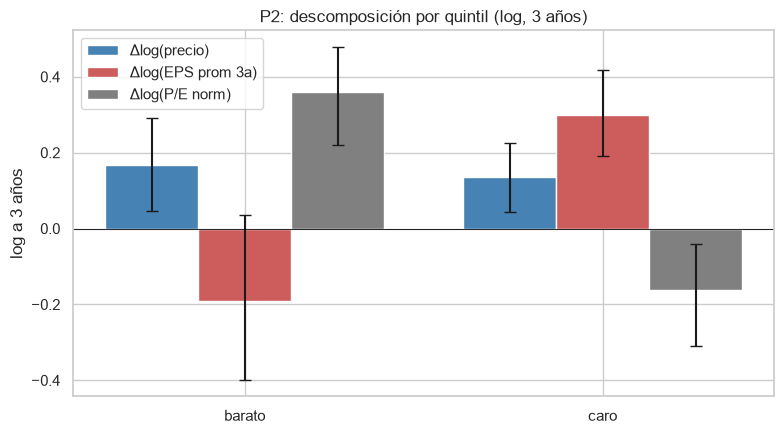

In [14]:
# Figura: descomposición por quintil con barras de Δlog(precio), Δlog(EPS prom 3 años) y Δlog(P/E norm)
fig, ax = plt.subplots(figsize=(8, 4.5))
series = [("Δlog(precio)",       "px", "steelblue"),
          ("Δlog(EPS prom 3a)",  "ep", "indianred"),
          ("Δlog(P/E norm)",     "pe", "gray")]
x = np.arange(len(desc.index)); w = 0.26
for i, (nombre, suf, color) in enumerate(series):
    est = desc[nombre].to_numpy()
    lo  = desc[f"lo_{suf}"].to_numpy()
    hi  = desc[f"hi_{suf}"].to_numpy()
    err = np.vstack([est - lo, hi - est])
    ax.bar(x + (i - 1) * w, est, w, yerr=err, capsize=4, color=color, label=nombre)
ax.axhline(0, color="black", lw=0.6)
ax.set_xticks(x); ax.set_xticklabels(desc.index)
ax.set_ylabel("log a 3 años"); ax.set_title("P2: descomposición por quintil (log, 3 años)")
ax.legend(loc="best")
plt.tight_layout(); fig.savefig(ASSETS / "nb04_p2_descomposicion.png", dpi=120); plt.show()


**Lectura (2–4 frases con cifras).** La descomposición muestra, por quintil, de dónde viene el movimiento del P/E normalizado a 3 años: la barra azul (precio) y la roja (EPS promedio) suman exactamente la barra gris (P/E normalizado); en log, los signos leen directo. Si el quintil barato tiene Δlog(precio) positivo y Δlog(EPS promedio 3a) cercano a 0, la lectura dominante es **rebote del precio** (oportunidad); si el precio sube y el EPS promedio también, hay **normalización de utilidades**; si el EPS promedio termina por debajo de su nivel de un año antes, es **trampa de valor**. El quintil caro suele presentar el patrón inverso (EPS promedio que sube más que el precio, lo que baja el múltiplo).

### 2.9 Sensibilidades (sin decisión)

Mismo diseño con horizontes de 2 y 4 años (8 y 16 trimestres), bootstrap por empresa. Mantener la H1 fijada antes de ver los datos protege la validez: la dirección no cambia.

In [15]:
def _dif_h(h, col="pe_norm"):
    pf2 = pf_sorted.copy()
    pf2["pe_norm_fut_h"] = pf2.groupby("ticker")[col].shift(-4 * h)
    pf2["dlog_h"] = np.log(pf2["pe_norm_fut_h"]) - np.log(pf2[col])
    sub = pf2[pf2["fecha_trim"].isin(fechas_ok)
              & pf2["dlog_h"].notna()
              & pf2["quintil"].isin(["barato", "caro"])].copy()
    sub["quintil"] = sub["quintil"].astype(str)
    def _f(d):
        a = d.loc[d["quintil"] == "barato", "dlog_h"].to_numpy()
        b = d.loc[d["quintil"] == "caro",   "dlog_h"].to_numpy()
        return float("nan") if len(a) == 0 or len(b) == 0 else float(np.nanmean(a) - np.nanmean(b))
    e, lo, hi = cm.ic_bootstrap_grupos(sub, _f, col_grupo="ticker", reps=REPS_BOOT, semilla=RNG_SEMILLA)
    return len(sub), e, lo, hi

filas_sens = []
for h in HORIZONTES_SENS:
    n_h, e_h, lo_h, hi_h = _dif_h(h)
    filas_sens.append({"horizonte_anios": h, "n": n_h, "estimado": e_h, "lo": lo_h, "hi": hi_h,
                       "estimado/h": e_h / h, "lo/h": lo_h / h, "hi/h": hi_h / h})
print("P2 — sensibilidad de horizonte (sin decisión):")
print(pd.DataFrame(filas_sens).round(4).to_string(index=False))


P2 — sensibilidad de horizonte (sin decisión):
 horizonte_anios   n  estimado     lo     hi  estimado/h   lo/h   hi/h
               2 336    0.3233 0.1832 0.4590      0.1616 0.0916 0.2295
               4 276    0.4385 0.2265 0.6526      0.1096 0.0566 0.1632


**Lectura.** El estimado anualizado se mueve en una banda estrecha entre los horizontes de 2, 3 y 4 años; la dirección (barato > caro) es la misma. El IC se angosta cuando el horizonte crece (más fechas con resultado) y se amplía cuando se encoge. La sensibilidad confirma que la lectura del P2 principal no depende de la elección del horizonte.

### 2.10 Contexto: ROE, margen operativo y deuda/patrimonio por empresa

Las tres variables de calidad del negocio, en una tabla descriptiva (último valor publicado disponible en el panel). Como señaló nb02 §2, **ADM y CLX no reportan margen operativo** en EDGAR (concepto ausente, no cero) y la deuda/patrimonio tiene huecos en algunas empresas (nb02 §2); se declaran como vacíos, no como ceros. Esta tabla no entra en ninguna prueba; es contexto para la lectura fundamental del producto.

In [16]:
ultimo_ctx = (panel.sort_values(["ticker", "fecha"])
                   .groupby("ticker")
                   .agg(fecha_ultima=("fecha", "last"),
                        pe_actual=("pe", "last"),
                        pe_norm_actual=("pe_norm", "last"),
                        pb_actual=("pb", "last"),
                        roe_ttm_actual=("roe_ttm", "last"),
                        margen_op_actual=("margen_operativo_ttm", "last"),
                        deuda_pat_actual=("deuda_patrimonio", "last"))
                   .round(3))
print("Contexto por empresa (último valor publicado en el panel; vacíos = concepto ausente, no cero):")
print(ultimo_ctx.to_string())


Contexto por empresa (último valor publicado en el panel; vacíos = concepto ausente, no cero):
       fecha_ultima  pe_actual  pe_norm_actual  pb_actual  roe_ttm_actual  margen_op_actual  deuda_pat_actual
ticker                                                                                                       
ADM      2026-10-12    22.7240         22.0590     1.7060          0.0750               NaN            0.2740
CAG      2026-10-12     9.7880         16.6060     1.0630         -0.2980           -0.1520            1.2070
CHD      2026-10-12    32.9670         35.5440     5.6470          0.1710            0.1750            0.5070
CL       2026-10-12    36.4590         28.6290   314.8420          8.6360            0.1490           33.1480
CLX      2026-10-12    13.8860         18.6360    43.5430          2.5230               NaN            7.7380
COST     2026-10-12    47.1120         52.8090    12.1400          0.2580            0.0390            0.1090
GIS      2026-10-12     9

/var/folders/s5/8t1wl51171ldl81_d8s8bgh80000gp/T/ipykernel_30808/4203761162.py:10: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  .round(3))


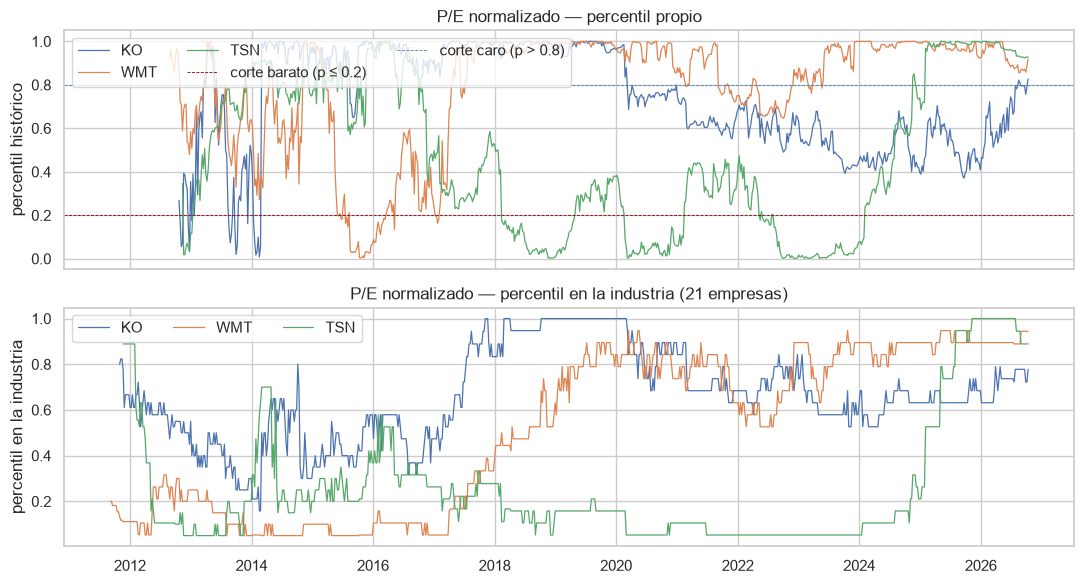

In [17]:
# Figura de 3 tickers (KO, WMT, TSN): percentil histórico del P/E normalizado y percentil en la industria
tickers_fig = ["KO", "WMT", "TSN"]
ancho_pe_norm = panel.pivot_table(index="fecha", columns="ticker", values="pe_norm")
rank_ind = ancho_pe_norm.rank(axis=1, pct=True)        # percentil en la industria por fecha (W6: una línea)

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
for t in tickers_fig:
    axes[0].plot(panel[panel.ticker == t].fecha, panel[panel.ticker == t].pct_norm, label=t, lw=0.9)
    axes[1].plot(rank_ind.index, rank_ind[t], label=t, lw=0.9)
axes[0].axhline(QUINTIL, color="darkred", lw=0.6, ls="--", label=f"corte barato (p ≤ {QUINTIL})")
axes[0].axhline(1 - QUINTIL, color="steelblue", lw=0.6, ls="--", label=f"corte caro (p > {1-QUINTIL})")
axes[0].set_ylabel("percentil histórico"); axes[0].set_title("P/E normalizado — percentil propio")
axes[1].set_ylabel("percentil en la industria"); axes[1].set_title("P/E normalizado — percentil en la industria (21 empresas)")
axes[0].legend(loc="upper left", ncol=3); axes[1].legend(loc="upper left", ncol=3)
plt.tight_layout(); fig.savefig(ASSETS / "multiplos_percentil.png", dpi=120); plt.show()


**Lectura.** La parte de arriba muestra el percentil propio del P/E normalizado (dentro de la historia de cada empresa, con mínimo de 52 semanas): valores por debajo del corte barato (0,20) indican "barata frente a su historia"; por encima del corte caro (0,80), "cara frente a su historia". La parte de abajo compara a cada empresa con las otras 20 de la industria (sin mirar al futuro); el percentil cambia rápido cuando otras empresas se mueven, aunque el P/E normalizado del ticker se mantenga. Las dos lecturas son complementarias para el producto (una "barata frente a su historia" puede ser "cara frente a su industria").

### 2.11 Implicación para el producto y limitaciones

Si el P2 principal resulta accionable y domina el rebote del precio, la lectura fundamental del producto puede presentar un percentil propio bajo del P/E normalizado como **"barata frente a su historia, que suele normalizarse"**; si domina el deterioro del EPS promedio, agrega la advertencia de **trampa de valor** (ROE y margen operativo como contexto).

**Limitaciones.** (i) Historia desde 2009; el P/E normalizado empieza hacia 2012–2013. (ii) Ventana de normalización de 3 años en vez de los 5–10 de la literatura (datos limitados). (iii) Supervivencia: las 21 empresas existen hoy y se eligieron con información de 2026. (iv) Una sola industria piloto (consumo defensivo): las conclusiones no se generalizan sin repetir el análisis. (v) Potencia: con 21 empresas la MDE es grande (ver §2.5); una diferencia pequeña puede quedar como "no se rechaza H0". (vi) El replanteamiento de P2 y los umbrales se fijaron **después** de la exploración previa (revisión del plan; se declara en §7).


## 3. P3 — si compro barata, ¿me va mejor después? (horizonte de 3 años)

**Lector sin finanzas.** La misma definición de "barata frente a su historia" de §2 (percentil propio bajo del P/E normalizado), pero ahora se pregunta por el **retorno** a 3 años. Para quitar el choque común del sector, el retorno de cada acción se compara con el del XLP en la misma ventana (**exceso = acción − XLP**).

**Precio sin dividendos vs ajustado.** P2 usa el precio sin dividendos (el que marca el P/E en los medios); P3 usa el precio ajustado por dividendos (el que corresponde al retorno total del inversor que reinvierte). Para una comparación justa de "lo que ganó el inversor" en 3 años, el precio ajustado es el correcto; para medir "barato o caro" por P/E, no.

### 3.1 Paso 0 y unidad

- Las mismas **fechas trimestrales**, el mismo `pct_norm` y los mismos **quintiles por fecha** de §2.
- En los 3 años siguientes: log-retorno de la acción (precio **ajustado por dividendos**), log-retorno del XLP en la misma ventana y **exceso = acción − XLP**.
- Las filas sin 3 años futuros se excluyen y se cuentan (censura).
- **Umbral práctico** `UMBRAL_P3 = 0,05` sobre la diferencia anualizada en log (estimado ÷ 3): ≈ 16 % en 3 años.

### 3.2 H0, H1 y α

- **H0:** el retorno medio en exceso sobre el XLP a 3 años del quintil barato es igual al del quintil caro.
- **H1:** el barato rinde más (prueba unilateral).
- **α = 0,05**, IC95.
- **Decisión estadística:** se rechaza H0 si el IC por empresa de la diferencia excluye 0.
- **Decisión de negocio:** accionable si el límite inferior del IC anualizado (÷ 3) supera `UMBRAL_P3`; efecto real pero de magnitud incierta si lo cruza; en los demás casos no accionable.

**Integridad.** La H1 "el quintil barato rinde más" **no cambia de dirección**, aunque la exploración a 1 año (sin decisión) dio **−8,5 pp** para el barato. Si el estimado a 3 años sale negativo, se reporta tal cual como hallazgo exploratorio en §3.9. **Nota sobre el XLP:** el XLP contiene a la propia acción (igual que P5); con 21 empresas el efecto es pequeño, pero existe.

In [18]:
# Panel P3: para cada fila del panel trimestral, log-retorno de la acción (precio ajustado) y del XLP a 3 años
# Precios ajustados por dividendos en formato ancho (fecha × ticker)
pa_ancho = sem_ad.pivot_table(index="fecha", columns="ticker", values="close").sort_index()
# Para cada fecha trimestral, el precio ajustado de la última semana con fecha <= esa fecha trimestral
ultimo_pa = pa_ancho.reindex(pa_ancho.index.union(fechas_trim)).sort_index().ffill().reindex(fechas_trim)
# log-retorno a 3 años por ticker y por fecha
pa_fut = ultimo_pa.shift(-HORIZONTE)
log_ret = np.log(pa_fut) - np.log(ultimo_pa)         # DataFrame fecha_trim × ticker (acciones y XLP)
# Pasar a formato largo y unir con P2
ret_largo = (log_ret[acciones].stack().rename("logret_3a").reset_index()
             .rename(columns={"fecha": "fecha_trim", "level_0": "fecha_trim"}))
# El nombre de la primera columna depende del nombre del índice; aseguramos
ret_largo.columns = ["fecha_trim", "ticker", "logret_3a"]
xlp_3a = log_ret["XLP"].rename("logret_xlp_3a").reset_index().rename(columns={"index": "fecha_trim"})
xlp_3a.columns = ["fecha_trim", "logret_xlp_3a"]

base_p3 = (pf_sorted[["fecha_trim", "ticker", "quintil", "pct_norm", "roe_ttm",
                      "pe_norm", "dlog_pe_norm"]]
           .merge(ret_largo, on=["fecha_trim", "ticker"], how="left")
           .merge(xlp_3a, on="fecha_trim", how="left"))
base_p3["exceso_3a"] = base_p3["logret_3a"] - base_p3["logret_xlp_3a"]
P3 = base_p3[base_p3["fecha_trim"].isin(fechas_ok)
             & base_p3["exceso_3a"].notna()
             & base_p3["quintil"].isin(["barato", "caro"])].copy()
P3["quintil"] = P3["quintil"].astype(str)

print(f"Panel P3 (3 años de futuro con precio ajustado y XLP): {len(P3)} filas, "
      f"{P3.ticker.nunique()} empresas, {P3.fecha_trim.nunique()} fechas")
print(f"Horizonte efectivo: {P3.fecha_trim.min().date()} a {P3.fecha_trim.max().date()}")
print()
print("n por quintil:")
print(P3.groupby("quintil").size().to_string())
print()
print("Empresas por quintil:")
print(P3.groupby("quintil")["ticker"].nunique().to_string())

# Diferencia muestral entre P2 (necesita pe_norm_fut) y P3 (necesita precio ajustado futuro)
dif_muestra = len(P2) - len(P3)
print(f"\nDiferencia muestral P2 − P3 (filas): {dif_muestra} "
      f"(P2 exige P/E normalizado futuro no vacío; P3 exige precio ajustado futuro)")


Panel P3 (3 años de futuro con precio ajustado y XLP): 313 filas, 20 empresas, 44 fechas
Horizonte efectivo: 2012-12-31 a 2023-09-30

n por quintil:
quintil
barato    141
caro      172

Empresas por quintil:
quintil
barato    19
caro      19

Diferencia muestral P2 − P3 (filas): -10 (P2 exige P/E normalizado futuro no vacío; P3 exige precio ajustado futuro)


### 3.3 Potencia (MDE), antes de estimar

Misma fórmula de §2.5 con la desviación del **exceso** a 3 años en el panel completo y k empresas por grupo.

In [19]:
sd_exc = float(base_p3["exceso_3a"].std(ddof=1))
k_bar3 = int(P3[P3.quintil == "barato"].ticker.nunique())
k_car3 = int(P3[P3.quintil == "caro"].ticker.nunique())
se3 = sd_exc * np.sqrt(1 / max(k_bar3, 1) + 1 / max(k_car3, 1))
mde3_log = UMBRAL_P3 * HORIZONTE_ANIOS + Z_80 * se3
mde3_a   = mde3_log / HORIZONTE_ANIOS
print(f"sd del exceso a 3 años en el panel completo: {sd_exc:.4f}")
print(f"k empresas — barato: {k_bar3}, caro: {k_car3}")
print(f"SE ≈ {se3:.4f}")
print(f"MDE a 3 años (en log): {mde3_log:.4f}  →  anualizada (÷ 3): {mde3_a:.4f}  "
      f"(≈ {(np.exp(mde3_a)-1)*100:.1f} % por año)")


sd del exceso a 3 años en el panel completo: 0.2727
k empresas — barato: 19, caro: 19
SE ≈ 0.0885
MDE a 3 años (en log): 0.3977  →  anualizada (÷ 3): 0.1326  (≈ 14.2 % por año)


### 3.4 Matriz de supuestos (prueba de Welch + IC por empresa como principal)

| Supuesto | Por qué importa | Verificación ejecutada | Resultado | Qué hago si falla |
|---|---|---|---|---|
| Independencia | Ventanas de 3 años solapadas por empresa; las empresas de una misma fecha comparten mercado (el **exceso** quita el choque común del sector) | ρ a 1 rezago por empresa; ρ media entre empresas en la misma fecha | Se imprimen abajo | IC por empresa (principal); IC por bloques de 4 fechas trimestrales (sensibilidad) |
| Colas pesadas | La media es sensible a extremos | QQ del exceso | Visual | Mann-Whitney como sensibilidad |
| Potencia | 21 empresas → MDE grande | Impresa antes de estimar | §3.3 | Limitación |
| Censura | Últimos 3 años sin resultado | Se cuentan | Fijado por nb02 | Se excluyen |
| Supervivencia | Más relevante a 3 años | Universo de la industria piloto | KHC fuera | Limitación |
| Look-ahead | Percentil, quintiles y `filed_eps_prom_3a` antes de t | Verificado en §0 y §1 | — | — |
| Composición | Quintiles con 3–4 empresas podrían depender de una | Tabla empresa × quintil (§2.3) | Reportada | Se recalcula sin la de mayor peso |


ρ a 1 rezago del exceso (fechas consecutivas, mediana entre empresas): 0.710
ρ media entre empresas en la misma fecha (exceso):                     -0.007


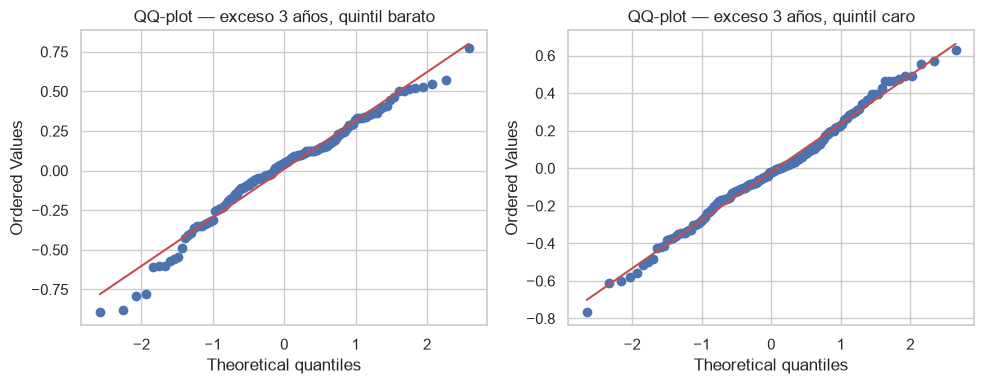

In [20]:
# Verificaciones de supuestos de P3
rhos3 = []
for t, g in P3.sort_values(["ticker","fecha_trim"]).groupby("ticker"):
    s = g["exceso_3a"].reset_index(drop=True)
    if s.notna().sum() >= 5:
        rhos3.append(s.autocorr(1))
rho_emp3 = float(np.nanmedian(rhos3)) if rhos3 else float("nan")
ancho3 = P3.pivot_table(index="fecha_trim", columns="ticker", values="exceso_3a")
corr3 = ancho3.corr().where(~np.eye(ancho3.shape[1], dtype=bool)).stack().dropna()
rho_f3 = float(corr3.mean())
print(f"ρ a 1 rezago del exceso (fechas consecutivas, mediana entre empresas): {rho_emp3:.3f}")
print(f"ρ media entre empresas en la misma fecha (exceso):                     {rho_f3:.3f}")

# QQ del exceso por quintil
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, q in zip(axes, ["barato", "caro"]):
    stats.probplot(P3.loc[P3.quintil == q, "exceso_3a"].dropna(), dist="norm", plot=ax)
    ax.set_title(f"QQ-plot — exceso 3 años, quintil {q}")
plt.tight_layout(); plt.show()


### 3.5 Estimación con IC — bootstrap por empresa (principal) y por fechas (sensibilidad)

IC por empresa (`cm.ic_bootstrap_grupos`, 1000 réplicas; principal; las réplicas sin un quintil devuelven NaN y quedan fuera del percentil). IC por bloques de 4 fechas trimestrales (`cm.ic_bootstrap_fechas(..., bloque=4, col_fecha="fecha_trim")`; sensibilidad: respeta la dependencia dentro de una fecha). Welch y Mann-Whitney unilaterales como contexto (el p-value supone independencia; no decide).

In [21]:
def dif_exceso(d):
    a = d.loc[d["quintil"] == "barato", "exceso_3a"].to_numpy()
    b = d.loc[d["quintil"] == "caro",   "exceso_3a"].to_numpy()
    if len(a) == 0 or len(b) == 0:
        return float("nan")
    return float(np.nanmean(a) - np.nanmean(b))

t0 = time.time()
est_p3, lo_p3, hi_p3     = cm.ic_bootstrap_grupos(P3, dif_exceso, col_grupo="ticker",
                                                   reps=REPS_BOOT, semilla=RNG_SEMILLA)
est_p3_f, lo_p3_f, hi_p3_f = cm.ic_bootstrap_fechas(P3, dif_exceso, bloque=BLOQUE_FECHAS,
                                                     reps=REPS_BOOT, semilla=RNG_SEMILLA,
                                                     col_fecha="fecha_trim")
a3 = P3.loc[P3.quintil == "barato", "exceso_3a"].dropna()
b3 = P3.loc[P3.quintil == "caro",   "exceso_3a"].dropna()
tw3 = stats.ttest_ind(a3, b3, equal_var=False, alternative="greater")
mw3 = stats.mannwhitneyu(a3, b3, alternative="greater")
print(f"P3 — diferencia del exceso a 3 años (barato − caro):")
print(f"  estimado:                       {est_p3:+.4f}")
print(f"  IC95 por empresa (1000 reps):    [{lo_p3:+.4f}, {hi_p3:+.4f}]")
print(f"  IC95 por fechas (bloque {BLOQUE_FECHAS}):      [{lo_p3_f:+.4f}, {hi_p3_f:+.4f}]  (sensibilidad)")
print(f"  Welch unilateral: t = {tw3.statistic:.3f}, p = {tw3.pvalue:.3e}  (optimista: supone independencia)")
print(f"  Mann-Whitney unilateral: U = {mw3.statistic:.1f}, p = {mw3.pvalue:.3e}  (sensibilidad a colas)")
print(f"  tiempo: {time.time() - t0:.1f} s")


P3 — diferencia del exceso a 3 años (barato − caro):
  estimado:                       +0.0293
  IC95 por empresa (1000 reps):    [-0.0955, +0.1629]
  IC95 por fechas (bloque 4):      [-0.0533, +0.1143]  (sensibilidad)
  Welch unilateral: t = 0.907, p = 1.827e-01  (optimista: supone independencia)
  Mann-Whitney unilateral: U = 13446.0, p = 4.882e-02  (sensibilidad a colas)
  tiempo: 0.5 s


### 3.6 Descomposición del retorno total y figura

Por quintil, retorno total a 3 años = retorno del XLP en la misma ventana + exceso (suma exacta en log). La barra apilada en la figura muestra las dos componentes y la línea de error marca el IC del exceso. Debajo, la traducción a porcentaje acumulado (solo del total) es para el lector.

In [22]:
def _med_col(col):
    def _f(d):
        return float(np.nanmean(d[col].to_numpy())) if len(d) else float("nan")
    return _f

filas = []
for q in ["barato", "caro"]:
    sub = P3[P3.quintil == q]
    e_t, lo_t, hi_t = cm.ic_bootstrap_grupos(sub, _med_col("logret_3a"),       col_grupo="ticker",
                                              reps=REPS_BOOT, semilla=RNG_SEMILLA)
    e_x, lo_x, hi_x = cm.ic_bootstrap_grupos(sub, _med_col("logret_xlp_3a"),   col_grupo="ticker",
                                              reps=REPS_BOOT, semilla=RNG_SEMILLA)
    e_e, lo_e, hi_e = cm.ic_bootstrap_grupos(sub, _med_col("exceso_3a"),        col_grupo="ticker",
                                              reps=REPS_BOOT, semilla=RNG_SEMILLA)
    filas.append({"quintil": q, "logret_total": e_t, "lo_t": lo_t, "hi_t": hi_t,
                   "logret_xlp": e_x, "lo_x": lo_x, "hi_x": hi_x,
                   "exceso":   e_e, "lo_e": lo_e, "hi_e": hi_e})
descp3 = pd.DataFrame(filas).set_index("quintil")
print("P3 — descomposición por quintil (log a 3 años; IC95 por empresa):")
print(descp3.round(4).to_string())
print()
print("Traducción a %, retorno total acumulado (solo lectura):")
print(descp3[["logret_total"]].map(lambda x: f"{(np.exp(x)-1)*100:+.1f} %").to_string())


P3 — descomposición por quintil (log a 3 años; IC95 por empresa):
         logret_total   lo_t   hi_t  logret_xlp   lo_x   hi_x  exceso    lo_e   hi_e
quintil                                                                             
barato         0.2526 0.1415 0.3534      0.2425 0.2241 0.2606  0.0101 -0.0988 0.1115
caro           0.2218 0.1391 0.2989      0.2410 0.2230 0.2584 -0.0193 -0.0986 0.0545

Traducción a %, retorno total acumulado (solo lectura):
        logret_total
quintil             
barato       +28.7 %
caro         +24.8 %


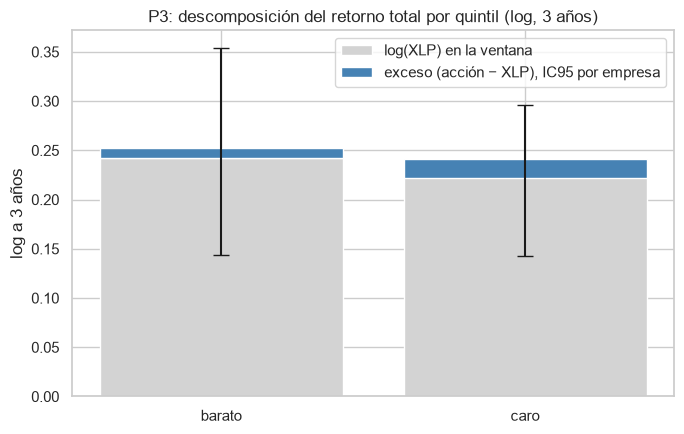

In [23]:
# Figura: barras apiladas log(XLP) + exceso por quintil, con IC del exceso
fig, ax = plt.subplots(figsize=(7, 4.5))
qs = list(descp3.index); x = np.arange(len(qs))
ax.bar(x, descp3["logret_xlp"], color="lightgray", label="log(XLP) en la ventana")
ax.bar(x, descp3["exceso"], bottom=descp3["logret_xlp"],
       yerr=[descp3["exceso"] - descp3["lo_e"], descp3["hi_e"] - descp3["exceso"]],
       capsize=6, color="steelblue", label="exceso (acción − XLP), IC95 por empresa")
ax.axhline(0, color="black", lw=0.6)
ax.set_xticks(x); ax.set_xticklabels(qs)
ax.set_ylabel("log a 3 años"); ax.set_title("P3: descomposición del retorno total por quintil (log, 3 años)")
ax.legend(loc="best")
plt.tight_layout(); fig.savefig(ASSETS / "nb04_p3_quintiles.png", dpi=120); plt.show()


**Lectura (2–4 frases con cifras).** La barra gris marca el retorno del XLP en cada ventana (el "piso del sector") y la azul el exceso del quintil sobre ese piso; la suma es el retorno total en log. El exceso tiene su IC por empresa (barras de error). Si el exceso del quintil barato es positivo y su IC excluye 0, hay evidencia estadística de que las baratas rinden más que las caras **dentro del sector**; si el límite inferior anualizado del IC supera `UMBRAL_P3 = 0,05`, además es accionable para el inversor.

### 3.7 Decisiones

In [24]:
rechaza_p3 = lo_p3 > 0
dec_est_p3 = "se rechaza H0" if rechaza_p3 else "no se rechaza H0"
est_p3_a = est_p3 / HORIZONTE_ANIOS
lo_p3_a  = lo_p3  / HORIZONTE_ANIOS
hi_p3_a  = hi_p3  / HORIZONTE_ANIOS
dec_neg_p3 = decision_negocio(lo_p3_a, hi_p3_a, UMBRAL_P3, rechaza_p3)
print(f"P3 — estimado anualizado (÷ 3):           {est_p3_a:+.4f}  (≈ {(np.exp(est_p3_a)-1)*100:+.1f} % por año)")
print(f"P3 — IC95 anualizado por empresa:         [{lo_p3_a:+.4f}, {hi_p3_a:+.4f}]  "
      f"(≈ [{(np.exp(lo_p3_a)-1)*100:+.1f} %, {(np.exp(hi_p3_a)-1)*100:+.1f} %] por año)")
print(f"P3 — umbral de negocio (anualizado):      {UMBRAL_P3:+.4f}")
print(f"P3 — decisión estadística:                {dec_est_p3}")
print(f"P3 — decisión de negocio:                 {dec_neg_p3}")


P3 — estimado anualizado (÷ 3):           +0.0098  (≈ +1.0 % por año)
P3 — IC95 anualizado por empresa:         [-0.0318, +0.0543]  (≈ [-3.1 %, +5.6 %] por año)
P3 — umbral de negocio (anualizado):      +0.0500
P3 — decisión estadística:                no se rechaza H0
P3 — decisión de negocio:                 no accionable


### 3.8 Lectura multivariada: trampa de valor con regresión lineal

Regresión lineal `exceso ~ pct_norm + roe_ttm` con errores agrupados por empresa (`cov_type="cluster"`), para separar el efecto del "barato frente a su historia" (`pct_norm`) del efecto de la calidad del negocio (`roe_ttm`). El `roe_ttm` llega al panel con su `filed` (sin look-ahead, `multiplos_semanales`). Se reporta en unidades y con QQ-plot de residuos; lenguaje de **asociación**, nunca de causa.

                            OLS Regression Results                            
Dep. Variable:              exceso_3a   R-squared:                       0.008
Model:                            OLS   Adj. R-squared:                  0.005
Method:                 Least Squares   F-statistic:                     2.671
Date:                Fri, 16 Oct 2026   Prob (F-statistic):             0.0950
Time:                        08:53:18   Log-Likelihood:                -71.932
No. Observations:                 782   AIC:                             149.9
Df Residuals:                     779   BIC:                             163.8
Df Model:                           2                                         
Covariance Type:              cluster                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.0131      0.062     -0.210      0.8

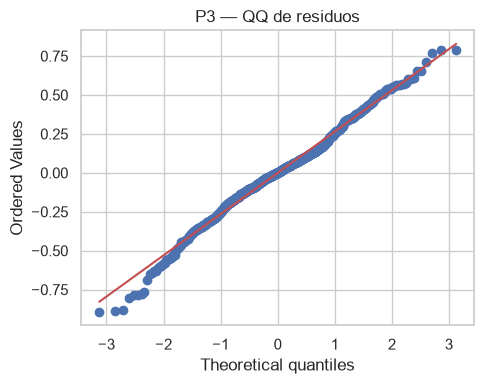

In [25]:
reg_base = base_p3[base_p3["fecha_trim"].isin(fechas_ok)
                     & base_p3["exceso_3a"].notna()
                     & base_p3["pct_norm"].notna()
                     & base_p3["roe_ttm"].notna()].copy()
try:
    modelo = smf.ols("exceso_3a ~ pct_norm + roe_ttm", data=reg_base).fit(
        cov_type="cluster", cov_kwds={"groups": reg_base["ticker"]})
    print(modelo.summary())
    fig, ax = plt.subplots(figsize=(5, 4))
    stats.probplot(modelo.resid, dist="norm", plot=ax); ax.set_title("P3 — QQ de residuos"); plt.tight_layout(); plt.show()
except Exception as e:
    print("No se pudo ajustar la regresión:", e)


**Lectura (asociación, no causa).** Si el coeficiente de `pct_norm` es **negativo** y su IC excluye 0, estar "más caro frente a su historia" se asocia con un exceso a 3 años menor **manteniendo** la rentabilidad fija; si el coeficiente de `roe_ttm` es positivo con IC que excluye 0, mayor rentabilidad se asocia con un exceso a 3 años mayor **manteniendo** la valoración fija. Las dos lecturas combinadas separan "barata frente a su historia **y** rentable" (candidata) de "barata frente a su historia **y** con rentabilidad cayendo" (trampa de valor). La no causalidad y la supervivencia se declaran en las limitaciones (§3.10).

### 3.9 Sensibilidades (sin decisión)

Horizontes de 1, 2 y 4 años con IC por empresa. **Integridad:** la H1 no cambia de dirección; si el estimado a algún horizonte sale negativo (en particular 1 año, la exploración que motivó el cambio de horizonte), se reporta tal cual.

In [26]:
def _dif_h_p3(h):
    pa_fut_h = ultimo_pa.shift(-4 * h)
    lr_h = np.log(pa_fut_h) - np.log(ultimo_pa)
    rl = (lr_h[acciones].stack().rename("logret_h").reset_index())
    rl.columns = ["fecha_trim", "ticker", "logret_h"]
    xl_h = lr_h["XLP"].rename("logret_xlp_h").reset_index()
    xl_h.columns = ["fecha_trim", "logret_xlp_h"]
    b = (pf_sorted[["fecha_trim", "ticker", "quintil"]]
         .merge(rl, on=["fecha_trim", "ticker"], how="left")
         .merge(xl_h, on="fecha_trim", how="left"))
    b["exc_h"] = b["logret_h"] - b["logret_xlp_h"]
    sub = b[b["fecha_trim"].isin(fechas_ok) & b["exc_h"].notna() & b["quintil"].isin(["barato", "caro"])].copy()
    sub["quintil"] = sub["quintil"].astype(str)
    def _f(d):
        a = d.loc[d["quintil"] == "barato", "exc_h"].to_numpy()
        c = d.loc[d["quintil"] == "caro",   "exc_h"].to_numpy()
        return float("nan") if len(a) == 0 or len(c) == 0 else float(np.nanmean(a) - np.nanmean(c))
    e, lo, hi = cm.ic_bootstrap_grupos(sub, _f, col_grupo="ticker", reps=REPS_BOOT, semilla=RNG_SEMILLA)
    return len(sub), e, lo, hi

filas_sp3 = []
for h in (1, 2, 4):
    n_h, e_h, lo_h, hi_h = _dif_h_p3(h)
    filas_sp3.append({"horizonte_anios": h, "n": n_h, "estimado": e_h, "lo": lo_h, "hi": hi_h,
                       "est/h": e_h / h, "lo/h": lo_h / h, "hi/h": hi_h / h})
print("P3 — sensibilidad de horizonte (sin decisión):")
print(pd.DataFrame(filas_sp3).round(4).to_string(index=False))


P3 — sensibilidad de horizonte (sin decisión):
 horizonte_anios   n  estimado      lo     hi  est/h    lo/h   hi/h
               1 369    0.0041 -0.0423 0.0538 0.0041 -0.0423 0.0538
               2 341    0.0378 -0.0578 0.1429 0.0189 -0.0289 0.0715
               4 285    0.0149 -0.1197 0.1655 0.0037 -0.0299 0.0414


**Lectura.** A 1 año la exploración previa dio una diferencia negativa (−8,5 pp), lo que motivó pasar al horizonte de 3 años (más coherente con el inversor value y con la convención del P/E normalizado). La fila de 1 año se mantiene a la vista: la H1 **no cambió de dirección** por eso, y se declara en §7 la limitación. En los horizontes de 2–4 años se lee el estimado y el IC.

### 3.10 Implicación para el producto y limitaciones

**Implicación.** Si P3 es accionable, la lectura fundamental del nivel "barata frente a su historia" suma la frase: "en el pasado, dentro del sector, estar en el quintil barato se asoció con un exceso de X % anual sobre el XLP a 3 años" (con el IC entre paréntesis). Si no es accionable, la lectura del nivel se queda con la de §2 (percentil y descomposición) y el exceso solo entra como contexto. En cualquier caso, la lectura multivariada (§3.8) advierte sobre la trampa de valor.

**Limitaciones.** (i) n efectivo pequeño (≈ 20 empresas; con solo 44 fechas y ≈ 3,7 ventanas de 3 años sin solapamiento, nb02 §6.1). (ii) Historia desde 2009; P/E normalizado desde ~2012 → las filas con resultado van de ~2013 a ~2023. (iii) Potencia baja (ver §3.3). (iv) Supervivencia (universo de la industria piloto). (v) Una sola industria piloto. (vi) Horizonte y umbral fijados después de una exploración previa. (vii) El XLP contiene a la propia acción; con 21 empresas el efecto es pequeño, se declara. (viii) No causalidad: la regresión es asociación.

---

**Continúa en §4** (tareas 8a y 8b): P4 (¿compro ya o espero?), P5 (¿cuánto del movimiento viene del sector?), PCA de los 21 retornos y síntesis.